<a href="https://colab.research.google.com/github/miskat-bcit/COMP-9170-Data-Science-Project/blob/Miskat/Iris_Analysis_Executed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 9170 Data Science Project
## Iris dataset: independent Python analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 1. Load the dataset
`X` contains four flower measurements. `y` is the species label.

In [ ]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
X = df[iris.feature_names]
y = df["target"]
print("Shape:", df.shape)
print("Species:", dict(enumerate(iris.target_names)))
print(df.head().to_string(index=False))

Shape: (150, 5)
Species: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target
               5.1               3.5                1.4               0.2       0
               4.9               3.0                1.4               0.2       0
               4.7               3.2                1.3               0.2       0
               4.6               3.1                1.5               0.2       0
               5.0               3.6                1.4               0.2       0


## 2. Data quality checks
Check missing values, duplicate rows, class balance, and measurement ranges.

In [ ]:
print("Missing values per column:\n", df.isna().sum())
print("Duplicate full rows:", df.duplicated().sum())
print("Class counts:\n", y.map(dict(enumerate(iris.target_names))).value_counts())
print("Descriptive statistics:\n", X.describe().round(3))
X.describe().round(3).to_csv("iris_descriptive_statistics.csv")

Missing values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
Duplicate full rows: 1
Class counts:
 target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Descriptive statistics:
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
count            150.000           150.000            150.000   
mean               5.843             3.057              3.758   
std                0.828             0.436              1.765   
min                4.300             2.000              1.000   
25%                5.100             2.800              1.600   
50%                5.800             3.000              4.350   
75%                6.400             3.300              5.100   
max                7.900             4.400              6.900   

       petal width (cm)  
count           150.000  
mean              1.199  
std               0.762  
min    

## 3. Explore the data
Compare petal length and petal width across species.

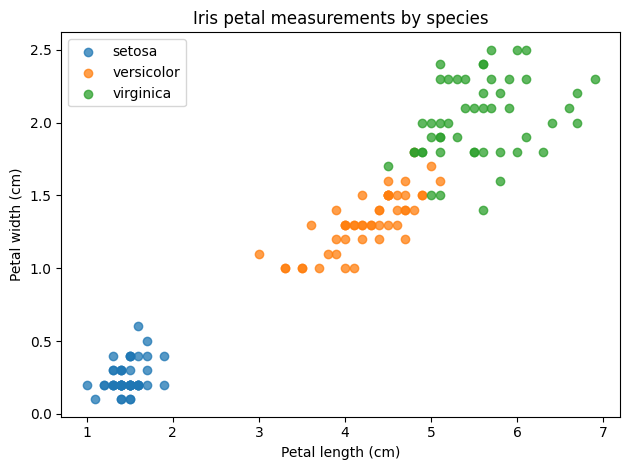

In [ ]:
for i, species in enumerate(iris.target_names):
    subset = df[df["target"] == i]
    plt.scatter(subset["petal length (cm)"], subset["petal width (cm)"], label=species, alpha=0.75)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris petal measurements by species")
plt.legend()
plt.tight_layout()
plt.savefig("iris_scatter.png", dpi=200)
plt.show()

## 4. Split into training and testing data
80% training and 20% testing. `stratify=y` keeps the species proportions similar. `random_state=42` makes the split repeatable.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 120
Test samples: 30


## 5. Train a simple decision tree
We use a maximum depth of 3 to keep the model easy to explain. The model only sees the training set during fitting.

In [ ]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=iris.target_names, zero_division=0))

Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 6. Confusion matrix
Rows are actual species; columns are predicted species. Diagonal entries are correct classifications.

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


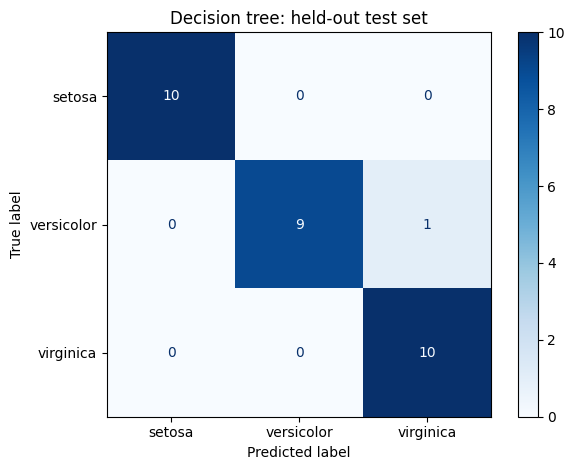

In [ ]:
cm = confusion_matrix(y_test, pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap="Blues")
plt.title("Decision tree: held-out test set")
plt.tight_layout()
plt.savefig("iris_confusion_matrix.png", dpi=200)
plt.show()

## 7. Five-fold cross-validation
Cross-validation provides a more stable estimate than one split. This is performed on the training portion only, keeping the test set untouched.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X_train, y_train, cv=cv, scoring="accuracy")
print("Fold accuracies:", scores.round(4))
print("Mean CV accuracy:", round(scores.mean(), 4))
print("CV standard deviation:", round(scores.std(ddof=1), 4))

Fold accuracies: [0.9583 1.     0.9583 0.9583 0.9167]
Mean CV accuracy: 0.9583
CV standard deviation: 0.0295


## 8. Save reproducible results
Keep these files as evidence.

In [ ]:
results = pd.DataFrame({"row_index": X_test.index, "actual": y_test.map(dict(enumerate(iris.target_names))).values, "predicted": pd.Series(pred).map(dict(enumerate(iris.target_names))).values})
results.to_csv("iris_test_predictions.csv", index=False)
print(results.head(10).to_string(index=False))

 row_index     actual  predicted
        38     setosa     setosa
       127  virginica  virginica
        57 versicolor versicolor
        93 versicolor versicolor
        42     setosa     setosa
        56 versicolor versicolor
        22     setosa     setosa
        20     setosa     setosa
       147  virginica  virginica
        84 versicolor versicolor


## 9. Comparison worksheet
Record AI statements verbatim, then check each against the Python results.

| Claim from AI | Evidence from Python | Agreement? | Explanation |
|---|---|---|---|
| Dataset has 150 observations | `df.shape` | Fill in | |
| No missing measurements | `df.isna().sum()` | Fill in | |
| Petal measurements separate species | Scatter plot | Fill in | |
| Expected classification accuracy | Test accuracy | Fill in | AI estimate is not a measured score |
